# Absorption + PVD: hypothesis research

Run cells top-to-bottom. Har section mein question, denominator aur interpretation diya hai. Future cells isi notebook mein add kar sakte hain.

**Hypotheses, conclusions nahi:**
- H1: absorption se pehle ke PVD reversal indication ka **opposite** next move predict karta hai.
- H2: absorption window ke andar PVD reversal indication ki **same direction** next move predict karti hai.
- H3: PVD absorption se disagree kare, toh absorption failures identify karne mein help kar sakta hai.

Reversal mapping for BOTH exhaustion and expansion: **DOWN-labelled PVD → UP prediction; UP-labelled PVD → DOWN prediction.** Expansion itself excessive move detect karta hai; reversal ek hypothesis hai, guarantee nahi.

Before = absorption START se pehle 5 trading bars. During = full 1/2/3/5D absorption window. Outcome = absorption END close se next 10 raw daily bars. Absorption uses existing longest-window deduplication.

Historical thresholds aur retrospective deduplication ke kaaran ye exploratory in-sample results hain. Observed pattern ko independent later dates par validate karna hoga. Related fronts/overlapping outcome windows independent samples nahi hain.


In [1]:
from pathlib import Path
import sys, importlib
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

ROOT = Path(r"C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis")
if str(ROOT.parent) not in sys.path:
    sys.path.insert(0, str(ROOT.parent))
import market_analysis.combined_signal_analysis.combined_signal_notebook as core
importlib.reload(core)

# EDIT THESE INPUTS before running.
REUSE_EXISTING_RUN = True
AS_OF = None                       # None = current local date, completed bars only
DATA_MODE = "auto"                  # CSV first, fetch only missing coverage; "cache" = offline
BEFORE_BARS = 5
FORWARD_BARS = 10
FLAT_BAND_TICKS = 0.0              # absolute terminal move <= this is FLAT
MIN_SAMPLE = 10                    # flag only; rare groups remain visible
VIEW_INSTRUMENT = None             # None = all; e.g. "BOZ26-F27"
pd.set_option("display.max_columns", 40)

def view(title, explanation, table):
    """Print interpretation next to EVERY displayed output."""
    display(Markdown("### " + title + "\n\n" + explanation))
    selected = table
    if VIEW_INSTRUMENT and "instrument" in selected:
        selected = selected.loc[selected.instrument.eq(VIEW_INSTRUMENT)]
    if selected.empty:
        print("No eligible observations. Check coverage/error table above.")
    else:
        display(selected.style.format(precision=2, na_rep="n/a"))


## 1. Data and threshold coverage

Existing RUN reuse fast hai. New RUN chahiye toh REUSE_EXISTING_RUN=False. Reused RUN ki actual dates/windows niche inspect karo; inputs badalne se old RUN automatically update nahi hota. Missing absorption thresholds wale instruments skip honge. Manual Excel sirf PVD thresholds ke liye hai.


In [3]:
if not REUSE_EXISTING_RUN or "RUN" not in globals():
    cfg = {**core.SETTINGS, "as_of": AS_OF, "data_mode": DATA_MODE,
           "before_bars": BEFORE_BARS, "forward_bars": FORWARD_BARS}
    RUN = core.run_combined_signal_analysis(settings=cfg)
print("Actual RUN settings:", {k: RUN["settings"].get(k) for k in
                              ["as_of", "before_bars", "forward_bars", "data_mode"]})
view("Data coverage", "actual_end dekho. Stale/missing data se recent outcomes incomplete ho sakte hain.", RUN["coverage"])
view("Skipped instruments / errors", "Ye instruments results ke denominator mein nahi hain.", RUN["errors"])


Manual workbook: 10 blank numeric-threshold rows skipped. Dates ignored. Inspect THRESHOLDS.attrs['manual_issues'].
Analyzing SMZ26-F27...
  [CACHE OK] SMZ26-F27: latest completed bar 2026-10-07; no API call
  17 unique absorption events; 40 first after-signal markers
Analyzing SMF27-H27...
  [CACHE OK] SMF27-H27: latest completed bar 2026-10-07; no API call
  13 unique absorption events; 24 first after-signal markers
Analyzing SMH27-K27...
  [CACHE OK] SMH27-K27: latest completed bar 2026-10-07; no API call
  13 unique absorption events; 34 first after-signal markers
Analyzing SMK27-N27...
  [CACHE OK] SMK27-N27: latest completed bar 2026-10-07; no API call
  9 unique absorption events; 20 first after-signal markers
Analyzing BOZ26-F27...
  [FETCH MISSING] BOZ26-F27: 2026-10-07 -> 2026-10-08 (end exclusive)
  12 unique absorption events; 25 first after-signal markers
Analyzing BOF27-H27...
  [FETCH MISSING] BOF27-H27: 2026-10-07 -> 2026-10-08 (end exclusive)
  7 unique absorption even

### Data coverage

actual_end dekho. Stale/missing data se recent outcomes incomplete ho sakte hain.

,instrument,product,raw_start,raw_end,analysis_bars,abs_events,cache_path,requested_start,requested_end,target_weekday_end,actual_start,actual_end,target_date_reached,api_requests,new_dates,fetch_status,cache_fallback_used,coverage_warning,coverage_basis,analysis_start,analysis_end,warmup_bars_available,warmup_bars_requested,warmup_sufficient
0,SMZ26-F27,SM,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,90,17,C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\data\sm\SMZ26-F27_1d.csv,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,2026-10-07 00:00:00+00:00,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,True,0,0,cache_only,False,,cached bars plus missing-range API updates; internal gaps/exchange holidays unverified,2026-06-01 00:00:00+00:00,2026-10-07 00:00:00+00:00,66,58,True
1,SMF27-H27,SM,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,90,13,C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\data\sm\SMF27-H27_1d.csv,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,2026-10-07 00:00:00+00:00,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,True,0,0,cache_only,False,,cached bars plus missing-range API updates; internal gaps/exchange holidays unverified,2026-06-01 00:00:00+00:00,2026-10-07 00:00:00+00:00,66,58,True
2,SMH27-K27,SM,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,90,13,C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\data\sm\SMH27-K27_1d.csv,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,2026-10-07 00:00:00+00:00,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,True,0,0,cache_only,False,,cached bars plus missing-range API updates; internal gaps/exchange holidays unverified,2026-06-01 00:00:00+00:00,2026-10-07 00:00:00+00:00,66,58,True
3,SMK27-N27,SM,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,90,9,C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\data\sm\SMK27-N27_1d.csv,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,2026-10-07 00:00:00+00:00,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,True,0,0,cache_only,False,,cached bars plus missing-range API updates; internal gaps/exchange holidays unverified,2026-06-01 00:00:00+00:00,2026-10-07 00:00:00+00:00,66,58,True
4,BOZ26-F27,BO,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,90,12,C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\data\bo\BOZ26-F27_1d.csv,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,2026-10-07 00:00:00+00:00,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,True,1,1,fetched,False,,cached bars plus missing-range API updates; internal gaps/exchange holidays unverified,2026-06-01 00:00:00+00:00,2026-10-07 00:00:00+00:00,66,58,True
5,BOF27-H27,BO,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,90,7,C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\data\bo\BOF27-H27_1d.csv,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,2026-10-07 00:00:00+00:00,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,True,1,1,fetched,False,,cached bars plus missing-range API updates; internal gaps/exchange holidays unverified,2026-06-01 00:00:00+00:00,2026-10-07 00:00:00+00:00,66,58,True
6,BOH27-K27,BO,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,90,22,C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\data\bo\BOH27-K27_1d.csv,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,2026-10-07 00:00:00+00:00,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,True,1,1,fetched,False,,cached bars plus missing-range API updates; internal gaps/exchange holidays unverified,2026-06-01 00:00:00+00:00,2026-10-07 00:00:00+00:00,66,58,True
7,BOK27-N27,BO,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,90,15,C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\data\bo\BOK27-N27_1d.csv,2026-02-25 00:00:00+00:00,2026-10-07 00:00:00+00:00,2026-10-0

### Skipped instruments / errors

Ye instruments results ke denominator mein nahi hain.

,instrument,stage,error
0,BOZ26-H27,threshold,Absorption threshold is missing/not a completed GPT-OSS choice


## 2. Measurement rules

**Direction accuracy** = correct terminal-direction predictions / full-horizon events with a prediction. FLAT counts as not correct; incomplete future excluded. No prediction/conflicting PVD excluded from accuracy, but coverage tables retain them.

**First barrier direction** = entry se configured required_move_ticks UP/DOWN target mein kaunsa pehle hit hua. Same bar mein dono hit = AMBIGUOUS; neither hit = NONE. Ye symmetric movement test hai, original ATR-stop trade label se alag hai.

**Original absorption success/failure** existing profit-before-stop rule se aata hai. FAILURE subgroup mein PVD direction accuracy batati hai ki terminal move explain hua ya nahi; alternative PVD trade profitable tha, ye prove nahi hota.


In [4]:
PVD_NAMES = ["DOWN_TREND_EXHAUSTION", "UP_TREND_EXHAUSTION",
             "DOWN_PRICE_EXPANSION", "UP_PRICE_EXPANSION"]
DIRECTION = {name: (1 if name.startswith("DOWN") else -1) for name in PVD_NAMES}

def build_research_events(run):
    """One row per retained absorption, plus explicit phase readiness and full raw forward path."""
    rows = []
    for instrument, result in run["instruments"].items():
        daily = result["daily"].reset_index(drop=True)
        raw = result["raw"].reset_index(drop=True)
        before = int(result["settings"]["before_bars"])
        horizon = int(result["settings"]["forward_bars"])
        tick = float(result["tick_size"])
        target = float(result["abs_params"]["required_move_ticks"])
        if target <= 0:
            raise ValueError("required_move_ticks must be positive for the first-barrier test")
        for event in result["events"].itertuples():
            start, end = int(event.window_start_index), int(event.signal_index)
            complete = end + horizon < len(raw)
            entry = float(raw.iloc[end].close)
            move = (float(raw.iloc[end+horizon].close)-entry)/tick if complete else np.nan
            actual = (0 if abs(move) <= FLAT_BAND_TICKS else int(np.sign(move))) if complete else np.nan
            first = "INCOMPLETE"
            if complete:
                first = "NONE"
                for bar in raw.iloc[end+1:end+horizon+1].itertuples():
                    up, down = bar.high >= entry+target*tick, bar.low <= entry-target*tick
                    if up or down:
                        first = "AMBIGUOUS" if up and down else "UP" if up else "DOWN"
                        break
            row = dict(event_id=event.event_id, instrument=instrument, product=result["threshold"]["product"],
                       date=event.Date, duration=int(event.candle_length), absorption_side=event.absorption_direction,
                       abs_prediction=1 if event.absorption_direction == "SELL" else -1,
                       outcome=event.outcome, research_payoff_ticks=getattr(event,"research_payoff_ticks",np.nan),
                       full_horizon=complete, terminal_move_ticks=move, actual_direction=actual,
                       first_barrier=first, horizon=horizon)
            for phase, left, right, expected in [
                ("before", max(0,start-before), start, before),
                ("during", start, end+1, end-start+1)]:
                part = daily.iloc[left:right]
                known = len(part)==expected and expected>0 and np.isfinite(part.pvd_z).all()
                comp_known = len(part)==expected and expected>0 and np.isfinite(part.compression_score).all()
                names = sorted(set(part.loc[part.pvd_signal.isin(PVD_NAMES),"pvd_signal"]))
                directions = {DIRECTION[n] for n in names}
                consensus = next(iter(directions)) if known and len(directions)==1 else np.nan
                row[phase+"_known"] = bool(known)
                row[phase+"_consensus"] = consensus
                row[phase+"_state"] = ("UNKNOWN" if not known else "NONE" if not names else
                                      "CONFLICT" if len(directions)>1 else "UP" if consensus==1 else "DOWN")
                row[phase+"_combination"] = "+".join(names) if known and names else "NONE" if known else "UNKNOWN"
                row[phase+"_compression_known"] = bool(comp_known)
                row[phase+"_compression"] = bool((part.compression_score >= result["settings"]["compression_threshold"]).any()) if comp_known else pd.NA
                for name in PVD_NAMES:
                    row[phase+"_"+name] = name in names if known else pd.NA
            rows.append(row)
    return pd.DataFrame(rows)

EVENTS = build_research_events(RUN)
if EVENTS.empty:
    raise RuntimeError("No absorption events available. Resolve coverage/threshold errors, then rerun.")
print("Retained absorption events:", len(EVENTS))


Retained absorption events: 131


## 3. Kitni baar kaunsa signal aaya?

**pct_all_absorptions** ka denominator instrument ke ALL retained absorption events hai—tumhara requested percentage. **pct_known_windows** sirf fully scored windows ka denominator use karta hai. Unknown windows ko 'signal absent' nahi maana.

Har type per window/event ek baar count, chahe same PVD 3 din repeat hua ho. Different type rows overlap, percentages add mat karna. Exact-combination table mutually exclusive hai; each phase ke percentages sum to 100% including UNKNOWN.


In [5]:
frequency, combos, baseline = [], [], []
for instrument, group in EVENTS.groupby("instrument", sort=True):
    full = group.loc[group.full_horizon]
    resolved = group.loc[group.outcome.isin(["SUCCESS","FAILURE"])]
    baseline.append(dict(instrument=instrument,total_absorptions=len(group),full_horizon=len(full),
                         up_pct=100*full.actual_direction.eq(1).mean(),
                         down_pct=100*full.actual_direction.eq(-1).mean(),
                         flat_pct=100*full.actual_direction.eq(0).mean(),
                         absorption_direction_accuracy_pct=100*full.actual_direction.eq(full.abs_prediction).mean(),
                         resolved_trades=len(resolved),
                         original_success_pct=100*resolved.outcome.eq("SUCCESS").mean()))
    for phase in ["before","during"]:
        for signal in PVD_NAMES+["compression"]:
            known_col = phase+"_compression_known" if signal=="compression" else phase+"_known"
            known = group[known_col]
            hits = group[phase+"_"+signal].fillna(False).astype(bool) & known
            frequency.append(dict(instrument=instrument,phase=phase,signal=signal,
                                  total_absorptions=len(group),known_windows=int(known.sum()),
                                  unknown_windows=int((~known).sum()),events_with_signal=int(hits.sum()),
                                  pct_all_absorptions=100*hits.sum()/len(group),
                                  pct_known_windows=100*hits.sum()/known.sum() if known.any() else np.nan))
        # Include compression presence with the exact PVD set.
        signatures = group[phase+"_combination"] + " | compression=" + group[phase+"_compression"].map(
            lambda x: "UNKNOWN" if pd.isna(x) else "YES" if x else "NO")
        for combination, count in signatures.value_counts().items():
            combos.append(dict(instrument=instrument,phase=phase,combination=combination,
                               n_events=count,pct_all_absorptions=100*count/len(group)))
BASELINE, FREQUENCY, COMBINATIONS = map(pd.DataFrame,[baseline,frequency,combos])
view("Absorption-only baseline", "UP/DOWN/FLAT percentages describe full-horizon market direction. Original success uses the separate target-before-stop rule.",BASELINE)
view("Signal occurrence percentages", "Example: events_with_signal=8 / total_absorptions=20 means 40%. Before/during are separate windows.",FREQUENCY)
view("Exact combinations including compression", "Find DOWN exhaustion + DOWN expansion together here. Repeated days do not increase event count.",COMBINATIONS)


### Absorption-only baseline

UP/DOWN/FLAT percentages describe full-horizon market direction. Original success uses the separate target-before-stop rule.

,instrument,total_absorptions,full_horizon,up_pct,down_pct,flat_pct,absorption_direction_accuracy_pct,resolved_trades,original_success_pct
0,BOF27-H27,7,7,14.29,71.43,14.29,42.86,5,80.00
1,BOH27-K27,22,19,10.53,78.95,10.53,47.37,15,60.00
2,BOK27-N27,15,15,20.00,80.00,0.00,60.00,13,61.54
3,BON27-Q27,23,20,20.00,80.00,0.00,65.00,18,55.56
4,BOZ26-F27,12,10,20.00,70.00,10.00,60.00,7,85.71
5,SMF27-H27,13,11,63.64,36.36,0.00,63.64,11,81.82
6,SMH27-K27,13,11,63.64,36.36,0.00,54.55,11,63.64
7,SMK27-N27,9,8,87.50,12.50,0.00,62.50,8,75.00
8,SMZ26-F27,17,15,40.00,53.33,6.67,53.33,15,93.33


### Signal occurrence percentages

Example: events_with_signal=8 / total_absorptions=20 means 40%. Before/during are separate windows.

,instrument,phase,signal,total_absorptions,known_windows,unknown_windows,events_with_signal,pct_all_absorptions,pct_known_windows
0,BOF27-H27,before,DOWN_TREND_EXHAUSTION,7,7,0,3,42.86,42.86
1,BOF27-H27,before,UP_TREND_EXHAUSTION,7,7,0,1,14.29,14.29
2,BOF27-H27,before,DOWN_PRICE_EXPANSION,7,7,0,4,57.14,57.14
3,BOF27-H27,before,UP_PRICE_EXPANSION,7,7,0,0,0.00,0.00
4,BOF27-H27,before,compression,7,7,0,2,28.57,28.57
5,BOF27-H27,during,DOWN_TREND_EXHAUSTION,7,7,0,1,14.29,14.29
6,BOF27-H27,during,UP_TREND_EXHAUSTION,7,7,0,2,28.57,28.57
7,BOF27-H27,during,DOWN_PRICE_EXPANSION,7,7,0,0,0.00,0.00
8,BOF27-H27,during,UP_PRICE_EXPANSION,7,7,0,1,14.29,14.29
9,BOF27-H27,during,compression,7,7,0,2,28.57,28.57


### Exact combinations including compression

Find DOWN exhaustion + DOWN expansion together here. Repeated days do not increase event count.

,instrument,phase,combination,n_events,pct_all_absorptions
0,BOF27-H27,before,DOWN_PRICE_EXPANSION | compression=NO,2,28.57
1,BOF27-H27,before,DOWN_PRICE_EXPANSION | compression=YES,1,14.29
2,BOF27-H27,before,DOWN_TREND_EXHAUSTION+UP_TREND_EXHAUSTION | compression=NO,1,14.29
3,BOF27-H27,before,DOWN_TREND_EXHAUSTION | compression=NO,1,14.29
4,BOF27-H27,before,DOWN_PRICE_EXPANSION+DOWN_TREND_EXHAUSTION | compression=YES,1,14.29
5,BOF27-H27,before,NONE | compression=NO,1,14.29
6,BOF27-H27,during,NONE | compression=NO,4,57.14
7,BOF27-H27,during,UP_PRICE_EXPANSION+UP_TREND_EXHAUSTION | compression=NO,1,14.29
8,BOF27-H27,during,UP_TREND_EXHAUSTION | compression=YES,1,14.29
9,BOF27-H27,during,DOWN_TREND_EXHAUSTION | compression=YES,1,14.29


## 4. H1/H2: before opposite, during same?

We test BOTH same-reversal and opposite-reversal predictions in BOTH phases, so result ko pre-assume nahi karte. **Consensus** uses all PVD types in a window: all indicate UP → UP; both UP and DOWN → conflict/no prediction. Individual-type rows also shown, even when another type disagrees.

**accuracy_pct** = terminal-direction accuracy. **abs_same_events_pct** = absorption direction on EXACT same events. **lift_pp** = their percentage-point difference. **majority_same_events_pct** = larger UP/DOWN proportion on that subset, a descriptive class-imbalance reference. **first_barrier_accuracy_pct** excludes NONE/AMBIGUOUS/INCOMPLETE and uses its own **n_clear_first_barrier** denominator.

Read n_evaluated and coverage first. High accuracy with tiny N is weak evidence. Rows overlap; don't add counts. H1 expected row = before/opposite; H2 = during/same.


In [6]:
def summarize_prediction(instrument, phase, source, rule, group, predictions):
    """Compare candidate and absorption on exactly the same eligible events."""
    predicted = predictions.notna()
    valid = predicted & group.full_horizon
    sample = group.loc[valid]
    pred = predictions.loc[valid]
    n = len(sample)
    accuracy = 100*sample.actual_direction.eq(pred).mean() if n else np.nan
    abs_accuracy = 100*sample.actual_direction.eq(sample.abs_prediction).mean() if n else np.nan
    clear = sample.first_barrier.isin(["UP","DOWN"])
    first_actual = sample.loc[clear,"first_barrier"].map({"UP":1,"DOWN":-1})
    failed = sample.loc[sample.outcome.eq("FAILURE")]
    resolved = group.loc[predicted & group.outcome.isin(["SUCCESS","FAILURE"])]
    return dict(instrument=instrument,phase=phase,source=source,rule=rule,
                total_absorptions=len(group),n_predictions=int(predicted.sum()),
                prediction_coverage_pct=100*predicted.mean(),n_evaluated=n,
                incomplete_predictions=int((predicted & ~group.full_horizon).sum()),
                accuracy_pct=accuracy,abs_same_events_pct=abs_accuracy,lift_pp=accuracy-abs_accuracy,
                majority_same_events_pct=100*max(sample.actual_direction.eq(1).mean(),sample.actual_direction.eq(-1).mean()) if n else np.nan,
                n_clear_first_barrier=int(clear.sum()),
                first_barrier_accuracy_pct=100*first_actual.eq(pred.loc[clear]).mean() if clear.any() else np.nan,
                n_ambiguous=int(sample.first_barrier.eq("AMBIGUOUS").sum()),
                n_no_barrier=int(sample.first_barrier.eq("NONE").sum()),
                resolved_abs_trades=len(resolved),
                original_abs_failure_pct=100*resolved.outcome.eq("FAILURE").mean() if len(resolved) else np.nan,
                n_full_horizon_abs_failures=len(failed),
                pvd_correct_on_abs_failure_pct=100*failed.actual_direction.eq(pred.loc[failed.index]).mean() if len(failed) else np.nan,
                low_sample=n<MIN_SAMPLE)

hypotheses=[]
for instrument, group in EVENTS.groupby("instrument"):
    for phase in ["before","during"]:
        for source in ["CONSENSUS"]+PVD_NAMES:
            if source=="CONSENSUS":
                base=group[phase+"_consensus"].astype(float)
            else:
                present=group[phase+"_"+source].fillna(False).astype(bool)
                base=pd.Series(np.where(present,DIRECTION[source],np.nan),index=group.index)
            for rule, multiplier in [("same_reversal",1),("opposite_reversal",-1)]:
                hypotheses.append(summarize_prediction(instrument,phase,source,rule,group,base*multiplier))
HYPOTHESES=pd.DataFrame(hypotheses)
view("H1/H2 consensus tests", "Focus: before/opposite_reversal and during/same_reversal. Compare lift_pp and sample size; do not choose solely by highest accuracy.",HYPOTHESES.loc[HYPOTHESES.source.eq("CONSENSUS")])
view("Individual PVD types", "Check whether the result holds for exhaustion AND expansion. A type can be present in a conflicting window; consensus table handles that separately.",HYPOTHESES.loc[~HYPOTHESES.source.eq("CONSENSUS")])


### H1/H2 consensus tests

Focus: before/opposite_reversal and during/same_reversal. Compare lift_pp and sample size; do not choose solely by highest accuracy.

,instrument,phase,source,rule,total_absorptions,n_predictions,prediction_coverage_pct,n_evaluated,incomplete_predictions,accuracy_pct,abs_same_events_pct,lift_pp,majority_same_events_pct,n_clear_first_barrier,first_barrier_accuracy_pct,n_ambiguous,n_no_barrier,resolved_abs_trades,original_abs_failure_pct,n_full_horizon_abs_failures,pvd_correct_on_abs_failure_pct,low_sample
0,BOF27-H27,before,CONSENSUS,same_reversal,7,5,71.43,5,0,20.00,40.00,-20.00,80.00,4,50.00,0,1,4,25.00,1,100.00,True
1,BOF27-H27,before,CONSENSUS,opposite_reversal,7,5,71.43,5,0,80.00,40.00,40.00,80.00,4,50.00,0,1,4,25.00,1,0.00,True
10,BOF27-H27,during,CONSENSUS,same_reversal,7,3,42.86,3,0,66.67,33.33,33.33,66.67,2,50.00,0,1,2,0.00,0,n/a,True
11,BOF27-H27,during,CONSENSUS,opposite_reversal,7,3,42.86,3,0,0.00,33.33,-33.33,66.67,2,50.00,0,1,2,0.00,0,n/a,True
20,BOH27-K27,before,CONSENSUS,same_reversal,22,10,45.45,8,2,0.00,50.00,-50.00,75.00,4,25.00,0,4,6,50.00,3,0.00,True
21,BOH27-K27,before,CONSENSUS,opposite_reversal,22,10,45.45,8,2,75.00,50.00,25.00,75.00,4,75.00,0,4,6,50.00,3,66.67,True
30,BOH27-K27,during,CONSENSUS,same_reversal,22,7,31.82,6,1,16.67,50.00,-33.33,50.00,4,25.00,0,2,4,50.00,2,50.00,True
31,BOH27-K27,during,CONSENSUS,opposite_reversal,22,7,31.82,6,1,50.00,50.00,0.00,50.00,4,75.00,0,2,4,50.00,2,0.00,True
40,BOK27-N27,before,CONSENSUS,same_reversal,15,8,53.33,8,0,37.50,62.50,-25.00,62.50,5,60.00,0,3,6,33.33,2,50.00,True
41,BOK27-N27,before,CONSENSUS,opposite_reversal,15,8,53.33,8,0,62.50,62.50,0.00,62.50,5,40.00,0,3,6,33.33,2,50.00,True


### Individual PVD types

Check whether the result holds for exhaustion AND expansion. A type can be present in a conflicting window; consensus table handles that separately.

,instrument,phase,source,rule,total_absorptions,n_predictions,prediction_coverage_pct,n_evaluated,incomplete_predictions,accuracy_pct,abs_same_events_pct,lift_pp,majority_same_events_pct,n_clear_first_barrier,first_barrier_accuracy_pct,n_ambiguous,n_no_barrier,resolved_abs_trades,original_abs_failure_pct,n_full_horizon_abs_failures,pvd_correct_on_abs_failure_pct,low_sample
2,BOF27-H27,before,DOWN_TREND_EXHAUSTION,same_reversal,7,3,42.86,3,0,0.00,66.67,-66.67,100.00,3,33.33,0,0,3,0.00,0,n/a,True
3,BOF27-H27,before,DOWN_TREND_EXHAUSTION,opposite_reversal,7,3,42.86,3,0,100.00,66.67,33.33,100.00,3,66.67,0,0,3,0.00,0,n/a,True
4,BOF27-H27,before,UP_TREND_EXHAUSTION,same_reversal,7,1,14.29,1,0,100.00,100.00,0.00,100.00,1,100.00,0,0,1,0.00,0,n/a,True
5,BOF27-H27,before,UP_TREND_EXHAUSTION,opposite_reversal,7,1,14.29,1,0,0.00,100.00,-100.00,100.00,1,0.00,0,0,1,0.00,0,n/a,True
6,BOF27-H27,before,DOWN_PRICE_EXPANSION,same_reversal,7,4,57.14,4,0,25.00,25.00,0.00,75.00,3,66.67,0,1,3,33.33,1,100.00,True
7,BOF27-H27,before,DOWN_PRICE_EXPANSION,opposite_reversal,7,4,57.14,4,0,75.00,25.00,50.00,75.00,3,33.33,0,1,3,33.33,1,0.00,True
8,BOF27-H27,before,UP_PRICE_EXPANSION,same_reversal,7,0,0.00,0,0,n/a,n/a,n/a,n/a,0,n/a,0,0,0,n/a,0,n/a,True
9,BOF27-H27,before,UP_PRICE_EXPANSION,opposite_reversal,7,0,0.00,0,0,n/a,n/a,n/a,n/a,0,n/a,0,0,0,n/a,0,n/a,True
12,BOF27-H27,during,DOWN_TREND_EXHAUSTION,same_reversal,7,1,14.29,1,0,0.00,0.00,0.00,0.00,0,n/a,0,1,0,n/a,0,n/a,True
13,BOF27-H27,during,DOWN_TREND_EXHAUSTION,opposite_reversal,7,1,14.29,1,0,0.00,0.00,0.00,0.00,0,n/a,0,1,0,n/a,0,n/a,True


## 5. Kya PVD absorption failures flag karta hai?

Predefined candidate: before consensus ko invert karo; during consensus ko same reversal direction rakho. Dono available aur disagree karein → CONFLICT; sirf ek available ho toh uski prediction. Within-window conflicting PVD ko bhi CONFLICT rakhte hain.

Groups **AGREE / DISAGREE / NO_PVD / CONFLICT** absorption ke comparison mein hain. Agar DISAGREE mein absorption failure rate consistently higher ho, future validation ke liye useful filter candidate ho sakta hai. **DISAGREE ko automatically reverse trade mat samajhna**: yahan reverse entry/stop payoff simulate nahi hua.


In [7]:
def candidate_prediction(row):
    """Combine the specified before-opposite / during-same hypothesis without outcome access."""
    if "CONFLICT" in [row.before_state,row.during_state]:
        return np.nan,"CONFLICT"
    votes=[]
    if pd.notna(row.before_consensus): votes.append(-row.before_consensus)
    if pd.notna(row.during_consensus): votes.append(row.during_consensus)
    if not votes: return np.nan,"NO_PVD"
    if len(set(votes))>1: return np.nan,"CONFLICT"
    prediction=votes[0]
    return prediction,"AGREE" if prediction==row.abs_prediction else "DISAGREE"

EVENTS[["candidate_prediction","candidate_group"]] = EVENTS.apply(
    lambda r: pd.Series(candidate_prediction(r)),axis=1)
failure_rows=[]
for (instrument, label), group in EVENTS.groupby(["instrument","candidate_group"]):
    resolved=group.loc[group.outcome.isin(["SUCCESS","FAILURE"])]
    valid=group.loc[group.full_horizon & group.candidate_prediction.notna()]
    failure_rows.append(dict(instrument=instrument,group=label,n_events=len(group),
                             pct_all_absorptions=100*len(group)/EVENTS.instrument.eq(instrument).sum(),
                             n_resolved=len(resolved),n_failures=int(resolved.outcome.eq("FAILURE").sum()),
                             absorption_failure_pct=100*resolved.outcome.eq("FAILURE").mean() if len(resolved) else np.nan,
                             n_direction_evaluated=len(valid),
                             candidate_direction_accuracy_pct=100*valid.actual_direction.eq(valid.candidate_prediction).mean() if len(valid) else np.nan,
                             abs_same_events_accuracy_pct=100*valid.actual_direction.eq(valid.abs_prediction).mean() if len(valid) else np.nan,
                             low_sample=len(resolved)<MIN_SAMPLE))
FAILURE_GROUPS=pd.DataFrame(failure_rows)
view("Failure association by PVD agreement", "Compare DISAGREE vs AGREE failure percentages within each instrument. Keep n_resolved alongside percentages. NO_PVD/CONFLICT are retained.",FAILURE_GROUPS)
view("Window consensus coverage", "CONFLICT means both reversal directions appeared. NONE means no PVD; UNKNOWN means insufficient scored bars.",EVENTS.groupby(["instrument","before_state","during_state"]).size().rename("n_events").reset_index())


### Failure association by PVD agreement

Compare DISAGREE vs AGREE failure percentages within each instrument. Keep n_resolved alongside percentages. NO_PVD/CONFLICT are retained.

,instrument,group,n_events,pct_all_absorptions,n_resolved,n_failures,absorption_failure_pct,n_direction_evaluated,candidate_direction_accuracy_pct,abs_same_events_accuracy_pct,low_sample
0,BOF27-H27,AGREE,3,42.86,3,1,33.33,3,66.67,66.67,True
1,BOF27-H27,CONFLICT,1,14.29,1,0,0.00,0,n/a,n/a,True
2,BOF27-H27,DISAGREE,3,42.86,1,0,0.00,3,66.67,0.00,True
3,BOH27-K27,AGREE,6,27.27,3,1,33.33,5,60.00,60.00,True
4,BOH27-K27,CONFLICT,12,54.55,9,3,33.33,0,n/a,n/a,True
5,BOH27-K27,NO_PVD,4,18.18,3,2,66.67,0,n/a,n/a,True
6,BOK27-N27,AGREE,4,26.67,3,0,0.00,4,100.00,100.00,True
7,BOK27-N27,CONFLICT,4,26.67,4,2,50.00,0,n/a,n/a,True
8,BOK27-N27,DISAGREE,5,33.33,4,2,50.00,5,60.00,40.00,True
9,BOK27-N27,NO_PVD,2,13.33,2,1,50.00,0,n/a,n/a,True


### Window consensus coverage

CONFLICT means both reversal directions appeared. NONE means no PVD; UNKNOWN means insufficient scored bars.

,instrument,before_state,during_state,n_events
0,BOF27-H27,CONFLICT,NONE,1
1,BOF27-H27,NONE,UP,1
2,BOF27-H27,UP,DOWN,2
3,BOF27-H27,UP,NONE,3
4,BOH27-K27,CONFLICT,CONFLICT,1
5,BOH27-K27,CONFLICT,NONE,3
6,BOH27-K27,CONFLICT,UP,3
7,BOH27-K27,DOWN,UP,1
8,BOH27-K27,NONE,CONFLICT,1
9,BOH27-K27,NONE,NONE,4


## 6. Individual cases + candles

Pick an event from the ledger: before/during combination → prediction → actual terminal direction → original trade outcome. A trade can succeed before stop but finish day 10 in the other direction. That is why both outcome fields are shown.

Charts retain existing marker names: DOWN expansion means actual expansion was downward; this notebook tests its **UP reversal hypothesis**. Chart arrows indicate the original signal/move, not guaranteed reversal. Shaded area = absorption detection window.


### Event-by-event audit

Direction numbers: +1=UP, -1=DOWN, 0=FLAT; n/a=incomplete/no prediction. Filter this table for the examples you noticed.

,event_id,instrument,date,duration,absorption_side,before_combination,during_combination,before_state,during_state,candidate_group,candidate_prediction,actual_direction,terminal_move_ticks,first_barrier,outcome,full_horizon
0,SMZ26-F27:2026-06-01:SELL:5d,SMZ26-F27,2026-06-01 00:00:00+00:00,5,SELL,DOWN_PRICE_EXPANSION+DOWN_TREND_EXHAUSTION,NONE,UP,NONE,DISAGREE,-1.00,-1.00,-7.00,DOWN,FAILURE,True
1,SMZ26-F27:2026-06-04:BUY:2d,SMZ26-F27,2026-06-04 00:00:00+00:00,2,BUY,NONE,NONE,NONE,NONE,NO_PVD,n/a,-1.00,-8.00,DOWN,SUCCESS,True
2,SMZ26-F27:2026-06-12:SELL:5d,SMZ26-F27,2026-06-12 00:00:00+00:00,5,SELL,NONE,DOWN_PRICE_EXPANSION+DOWN_TREND_EXHAUSTION+UP_TREND_EXHAUSTION,NONE,CONFLICT,CONFLICT,n/a,1.00,6.00,UP,SUCCESS,True
3,SMZ26-F27:2026-06-24:BUY:5d,SMZ26-F27,2026-06-24 00:00:00+00:00,5,BUY,DOWN_TREND_EXHAUSTION+UP_TREND_EXHAUSTION,NONE,CONFLICT,NONE,CONFLICT,n/a,-1.00,-3.00,AMBIGUOUS,SUCCESS,True
4,SMZ26-F27:2026-07-02:SELL:1d,SMZ26-F27,2026-07-02 00:00:00+00:00,1,SELL,NONE,NONE,NONE,NONE,NO_PVD,n/a,-1.00,-1.00,UP,SUCCESS,True
5,SMZ26-F27:2026-07-10:SELL:2d,SMZ26-F27,2026-07-10 00:00:00+00:00,2,SELL,NONE,NONE,NONE,NONE,NO_PVD,n/a,-1.00,-8.00,AMBIGUOUS,SUCCESS,True
6,SMZ26-F27:2026-07-13:BUY:1d,SMZ26-F27,2026-07-13 00:00:00+00:00,1,BUY,NONE,NONE,NONE,NONE,NO_PVD,n/a,-1.00,-10.00,AMBIGUOUS,SUCCESS,True
7,SMZ26-F27:2026-07-29:SELL:2d,SMZ26-F27,2026-07-29 00:00:00+00:00,2,SELL,DOWN_PRICE_EXPANSION,DOWN_PRICE_EXPANSION,UP,UP,CONFLICT,n/a,1.00,6.00,UP,SUCCESS,True
8,SMZ26-F27:2026-08-10:SELL:5d,SMZ26-F27,2026-08-10 00:00:00+00:00,5,SELL,DOWN_PRICE_EXPANSION,DOWN_TREND_EXHAUSTION+UP_TREND_EXHAUSTION,UP,CONFLICT,CONFLICT,n/a,-1.00,-1.00,UP,SUCCESS,True
9,SMZ26-F27:2026-08-12:SELL:2d,SMZ26-F27,2026-08-12 00:00:00+00:00,2,SELL,DOWN_TREND_EXHAUSTION+UP_TREND_EXHAUSTION,UP_TREND_EXHAUSTION,CONFLICT,DOWN,CONFLICT,n/a,0.00,0.00,UP,SUCCESS,True


**SMZ26-F27:2026-06-01:SELL:5d** — DISAGREE; original outcome=FAILURE; terminal move=-7.00 ticks

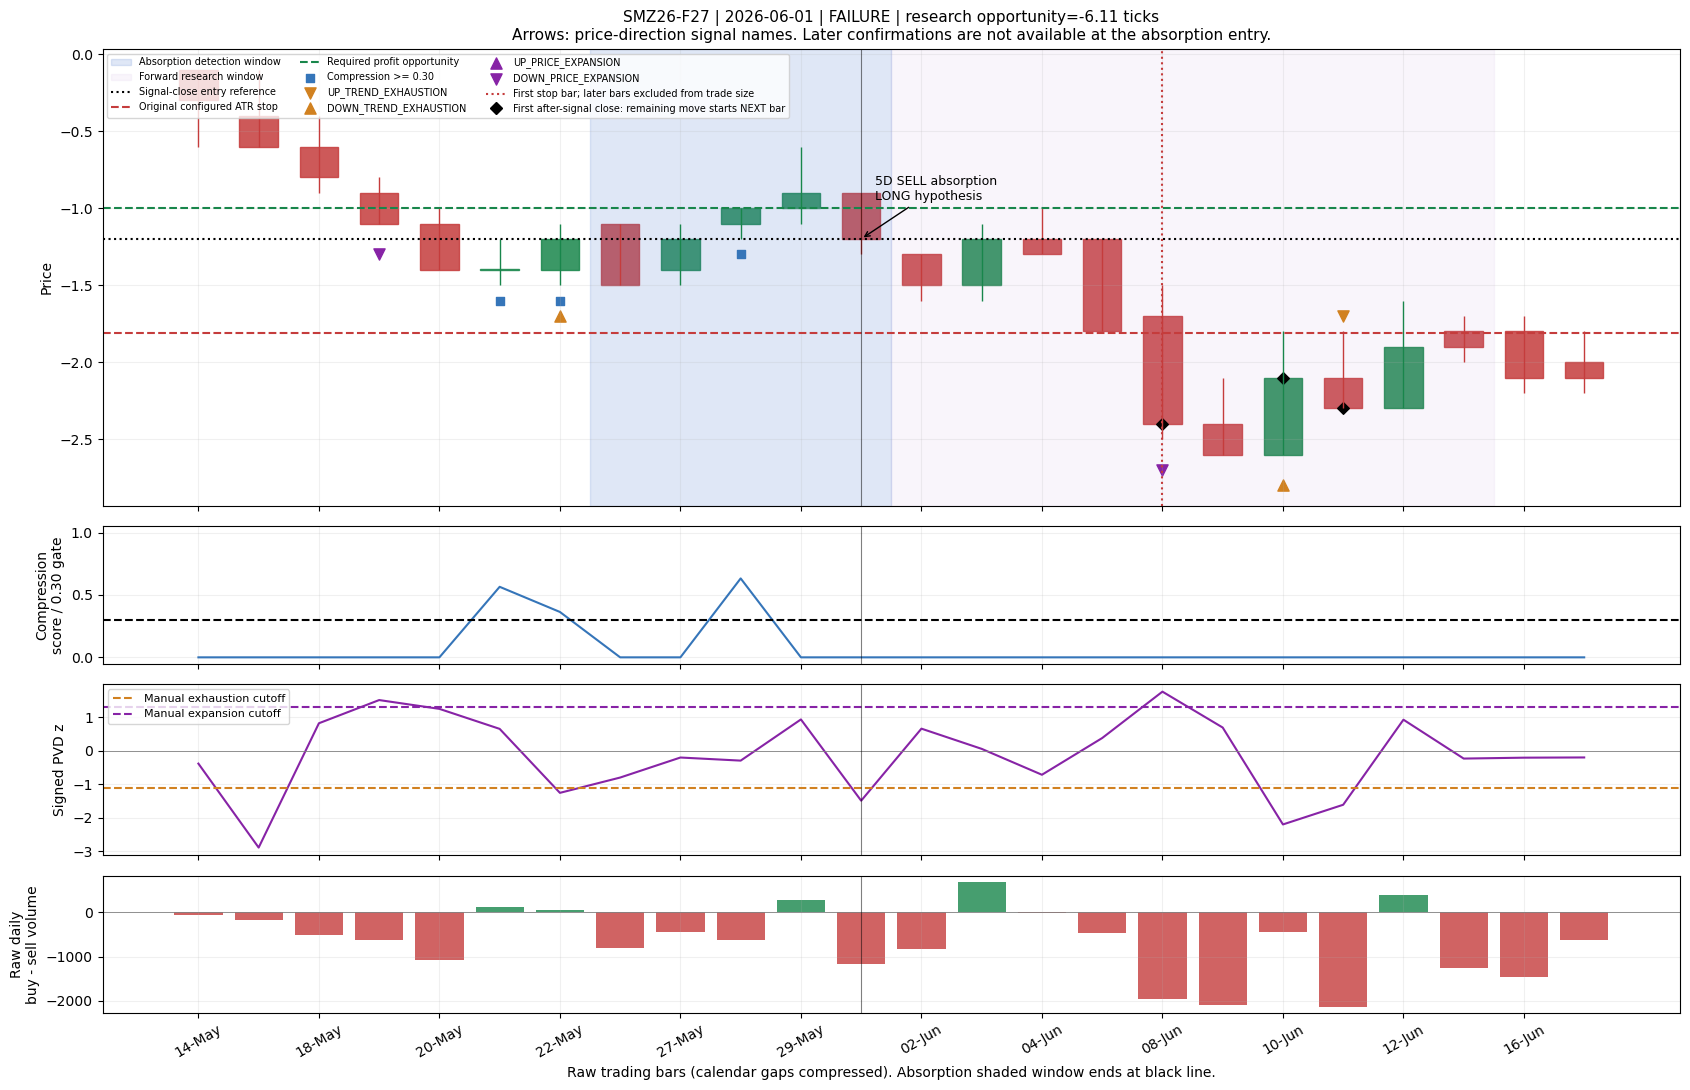

**BOH27-K27:2026-06-01:BUY:1d** — CONFLICT; original outcome=SUCCESS; terminal move=-1.50 ticks

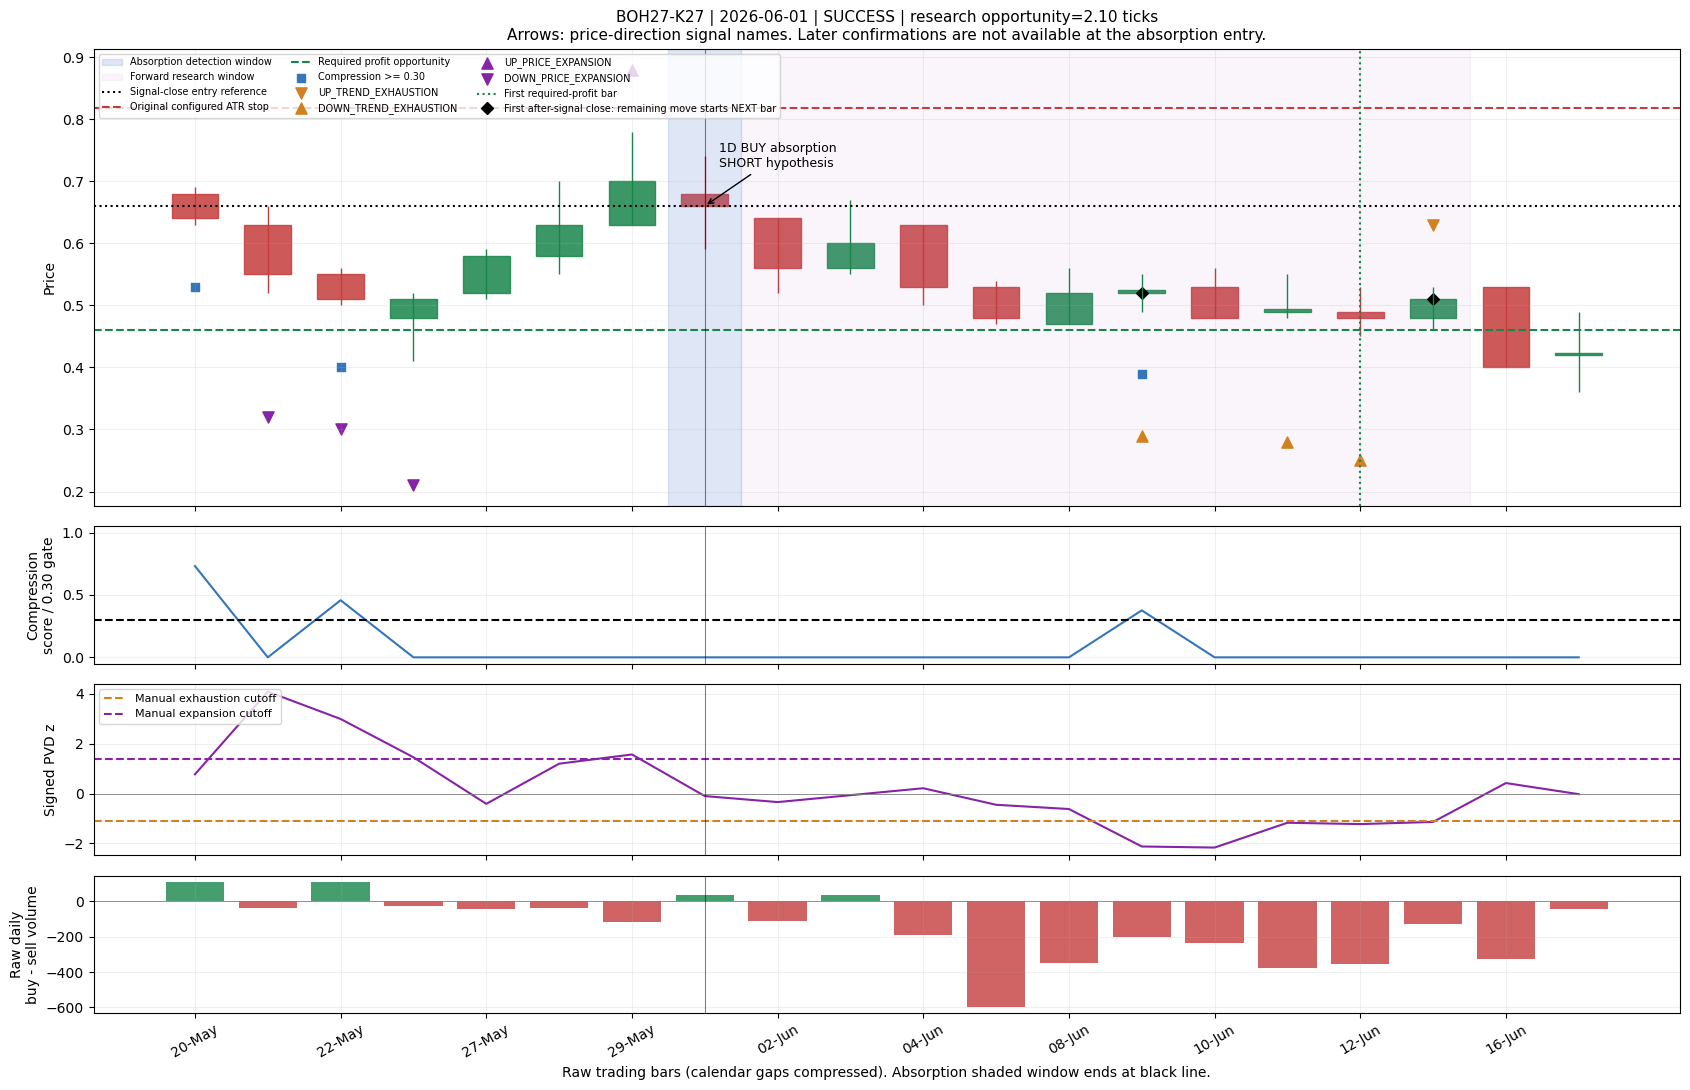

**BOZ26-F27:2026-06-02:BUY:5d** — AGREE; original outcome=SUCCESS; terminal move=-2.80 ticks

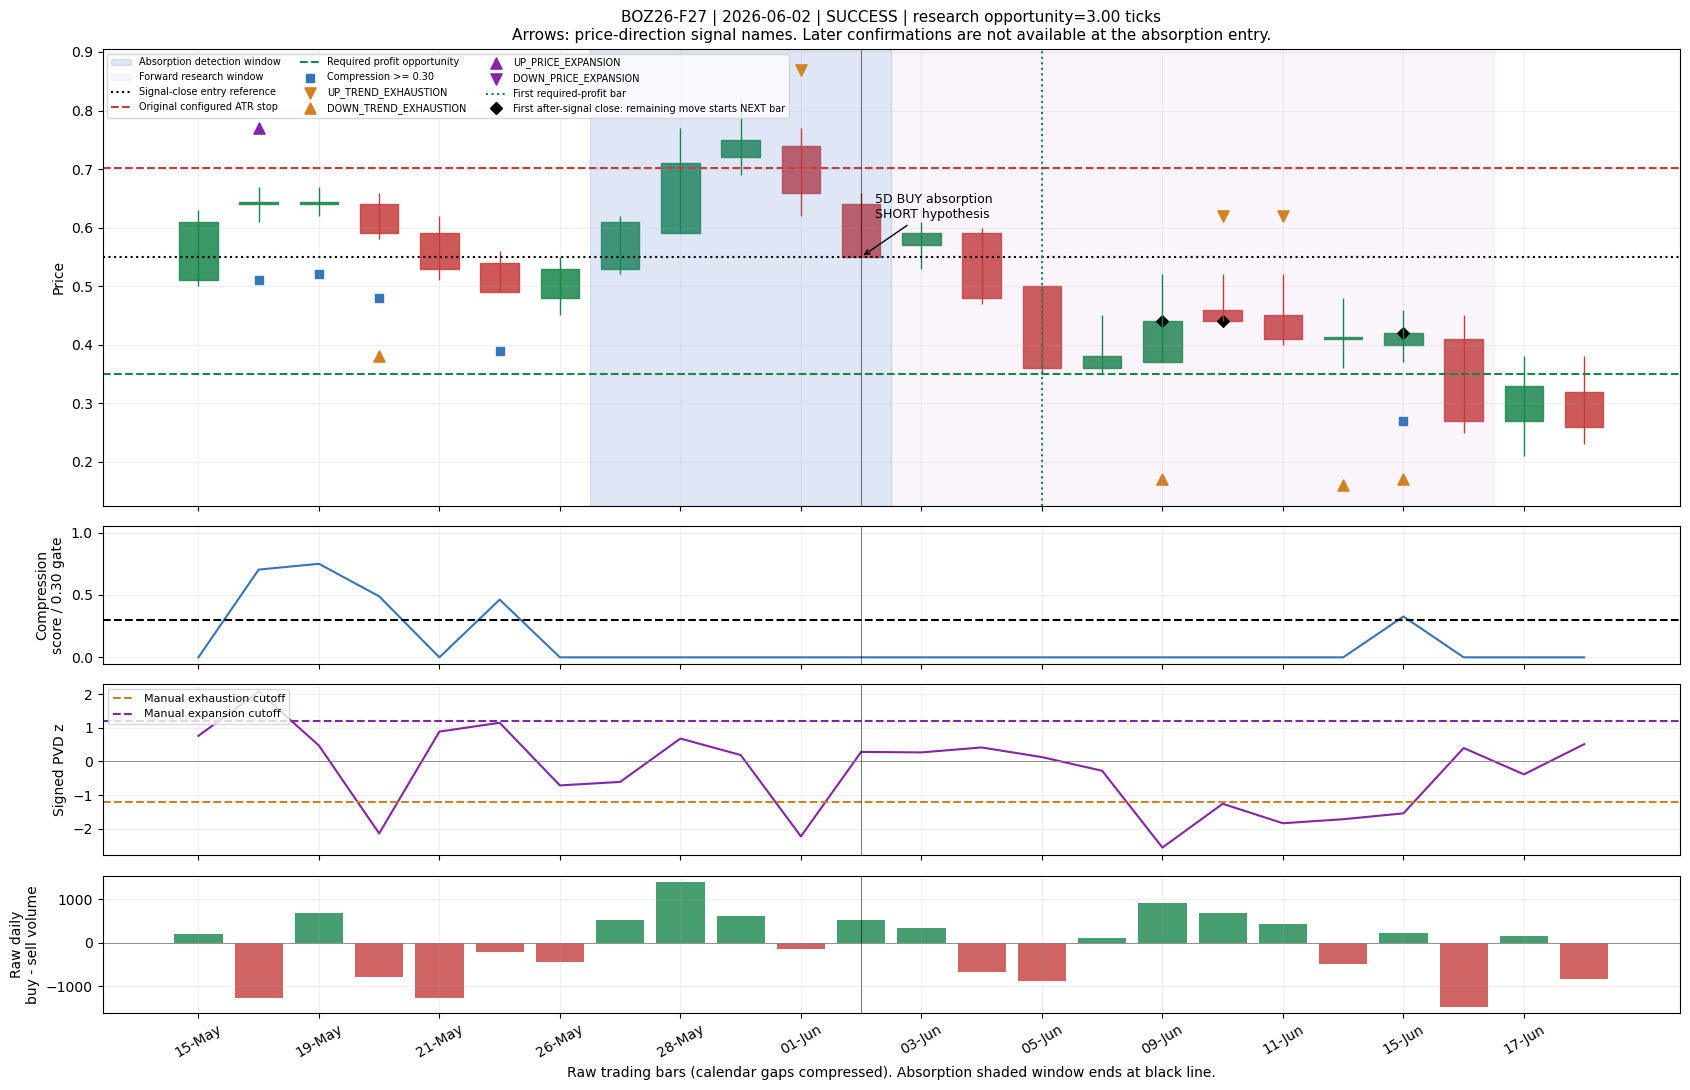

**SMZ26-F27:2026-06-04:BUY:2d** — NO_PVD; original outcome=SUCCESS; terminal move=-8.00 ticks

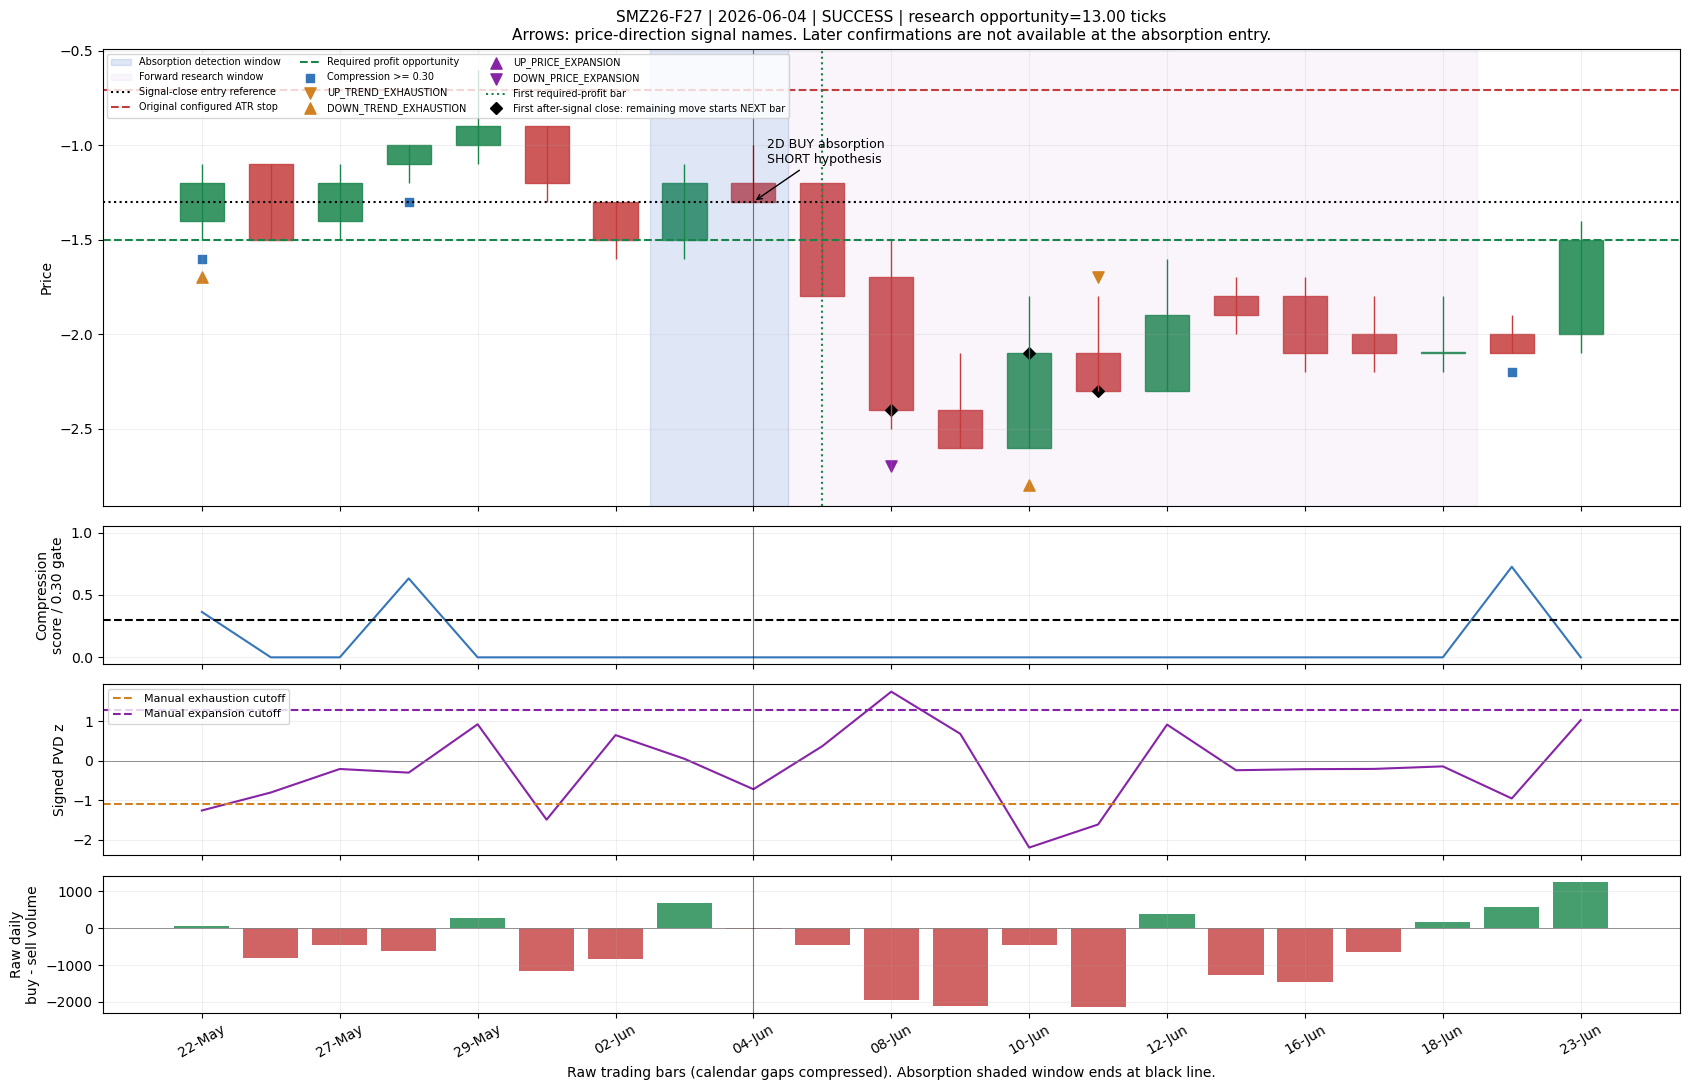

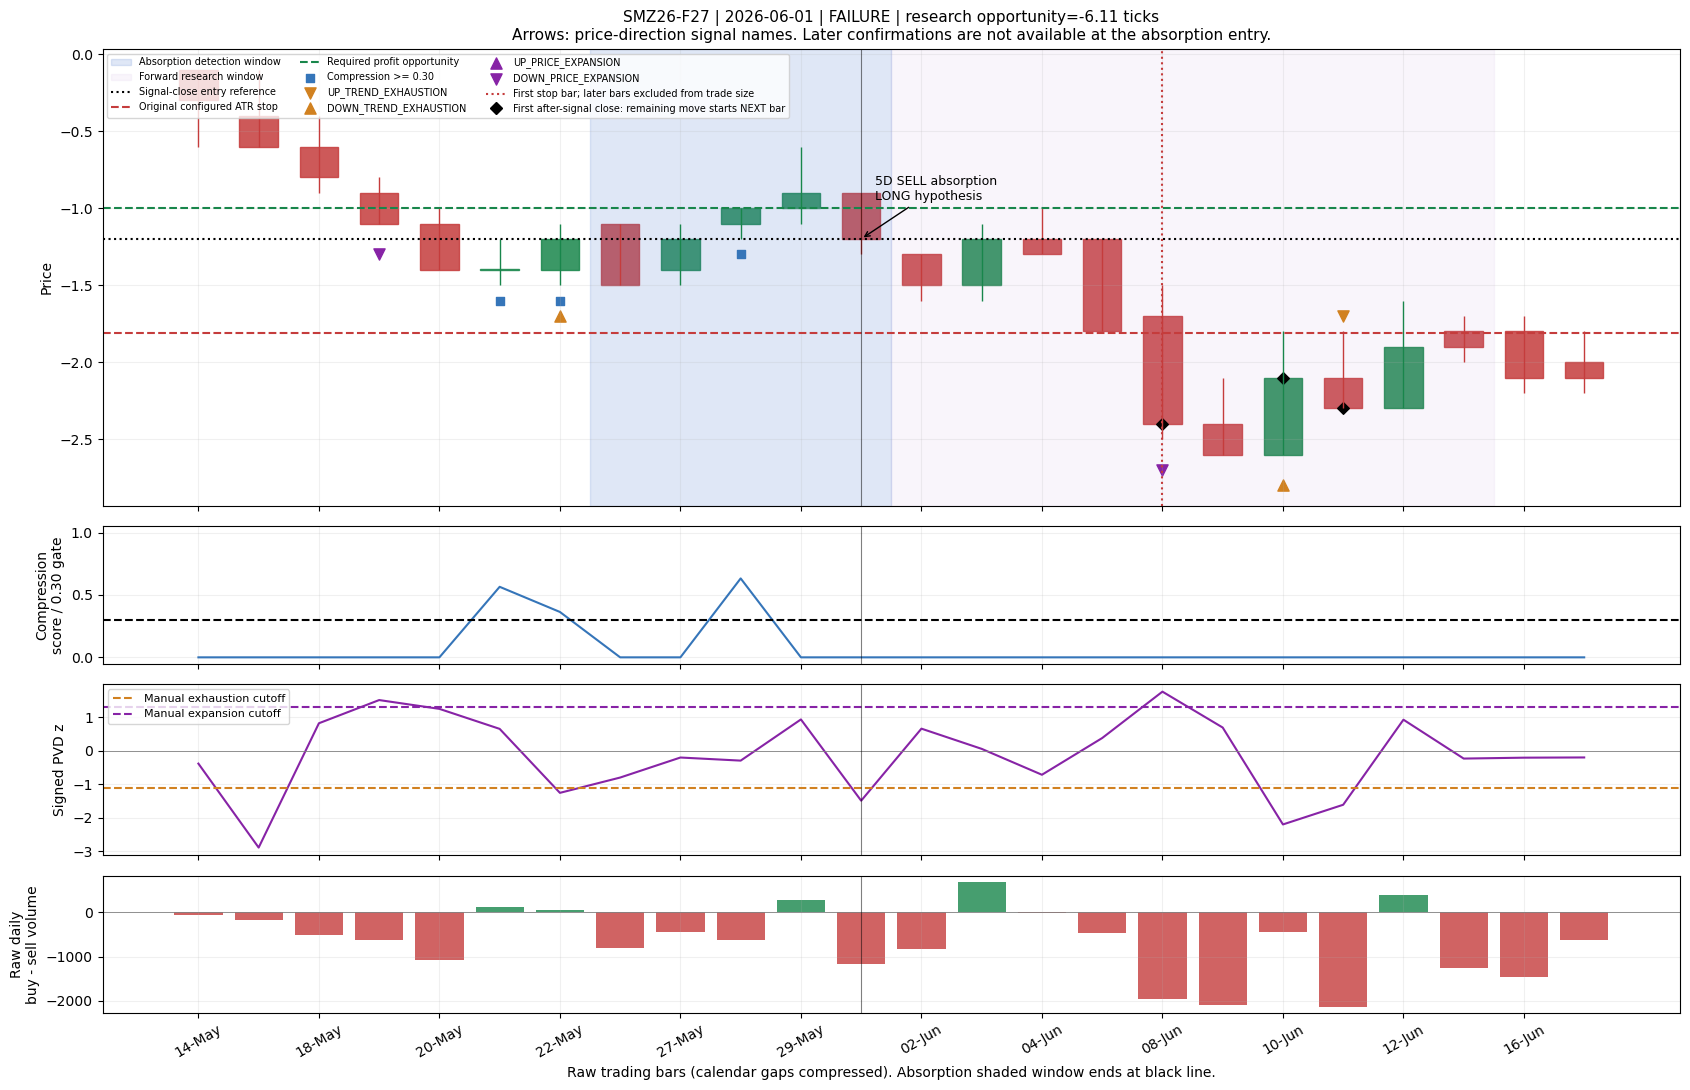

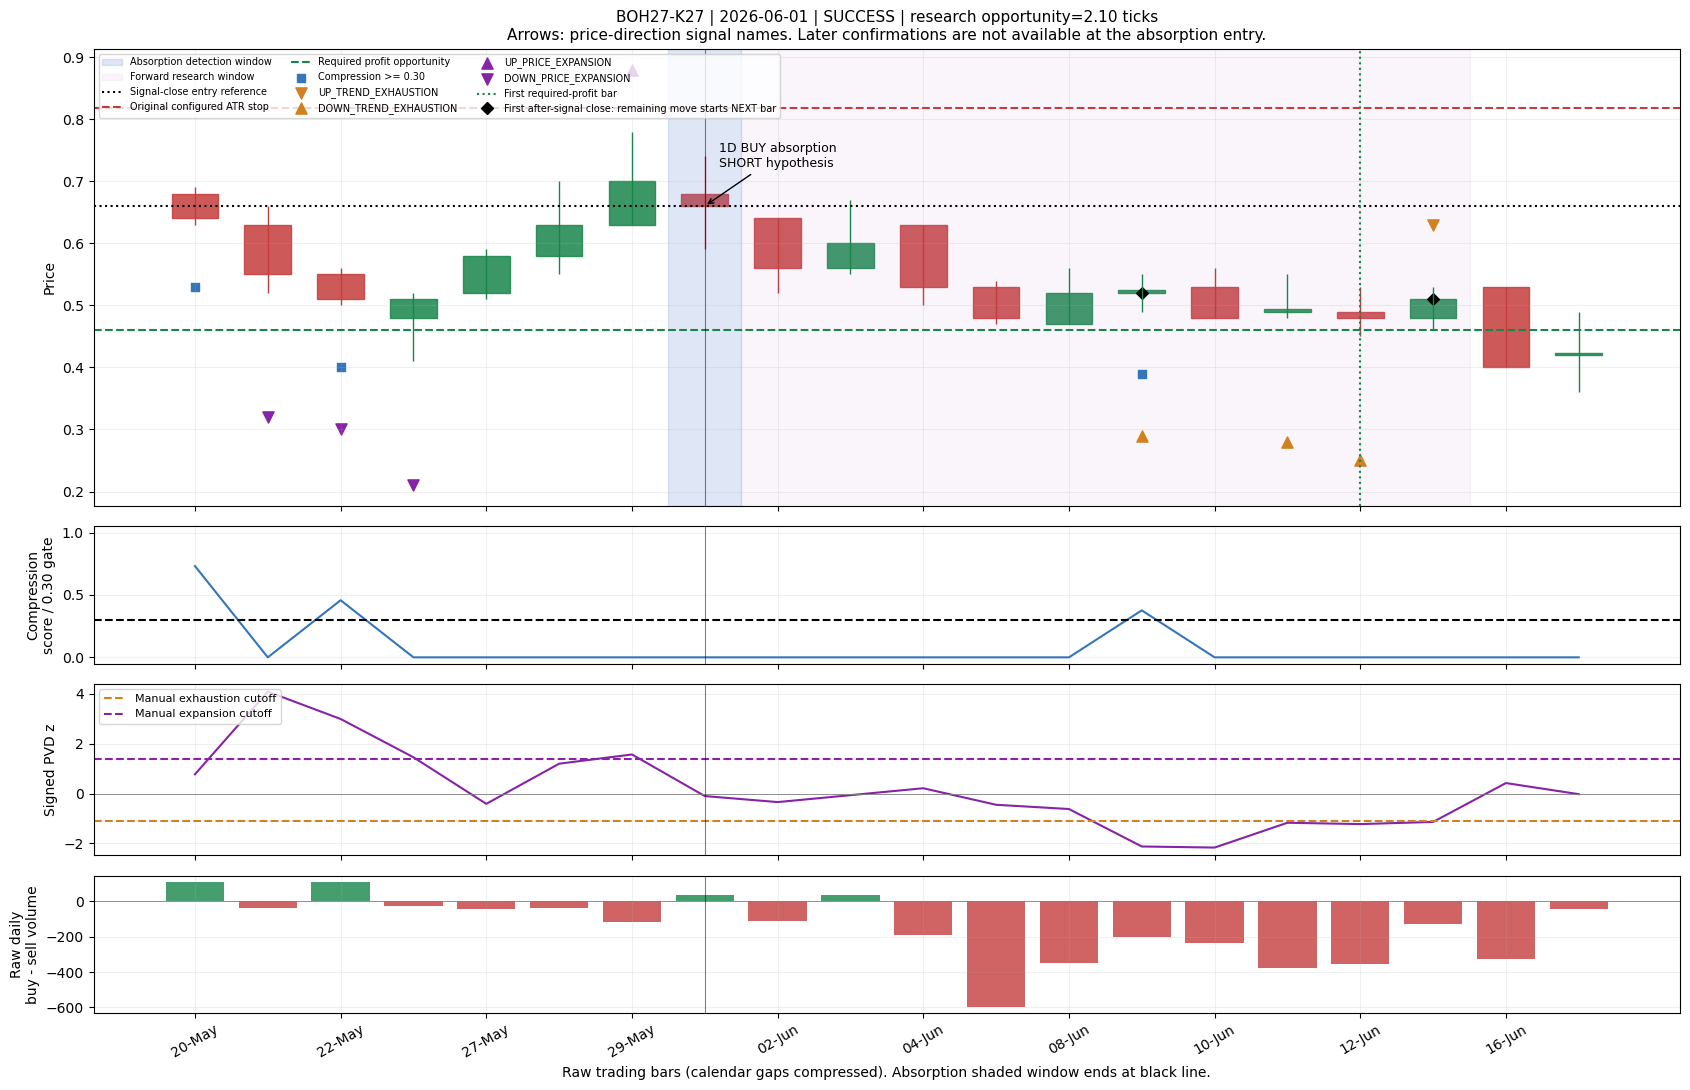

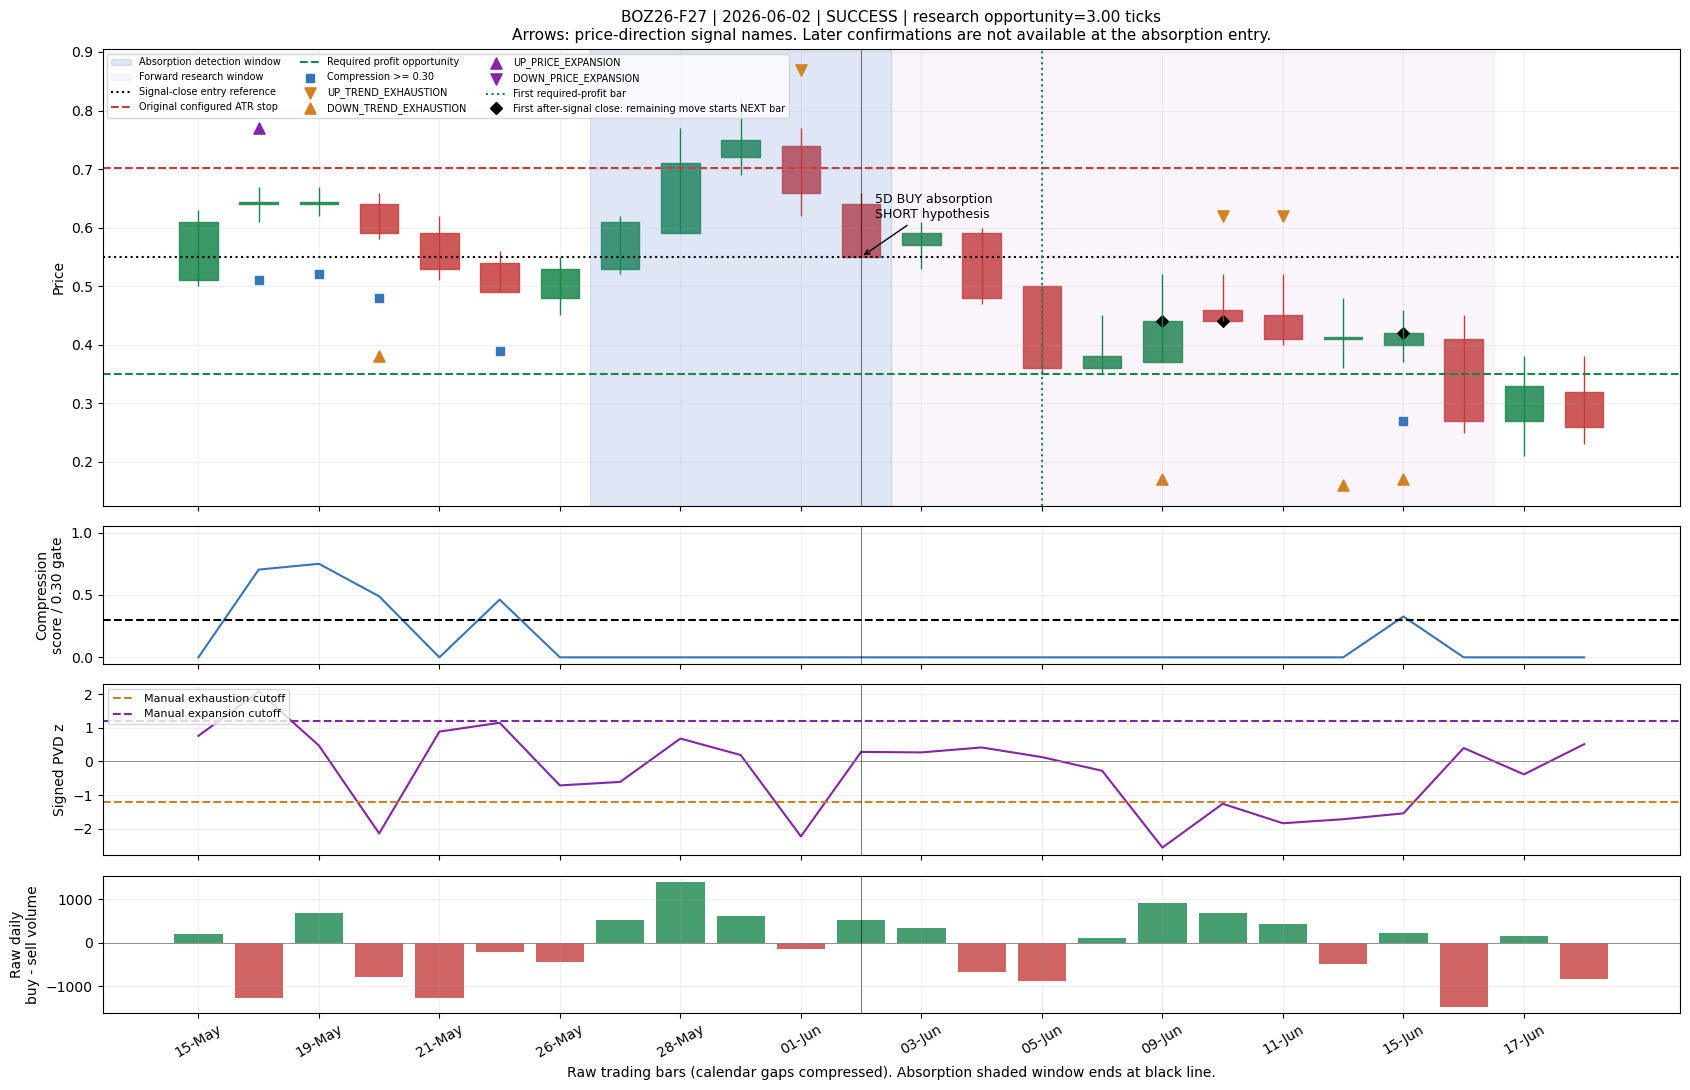

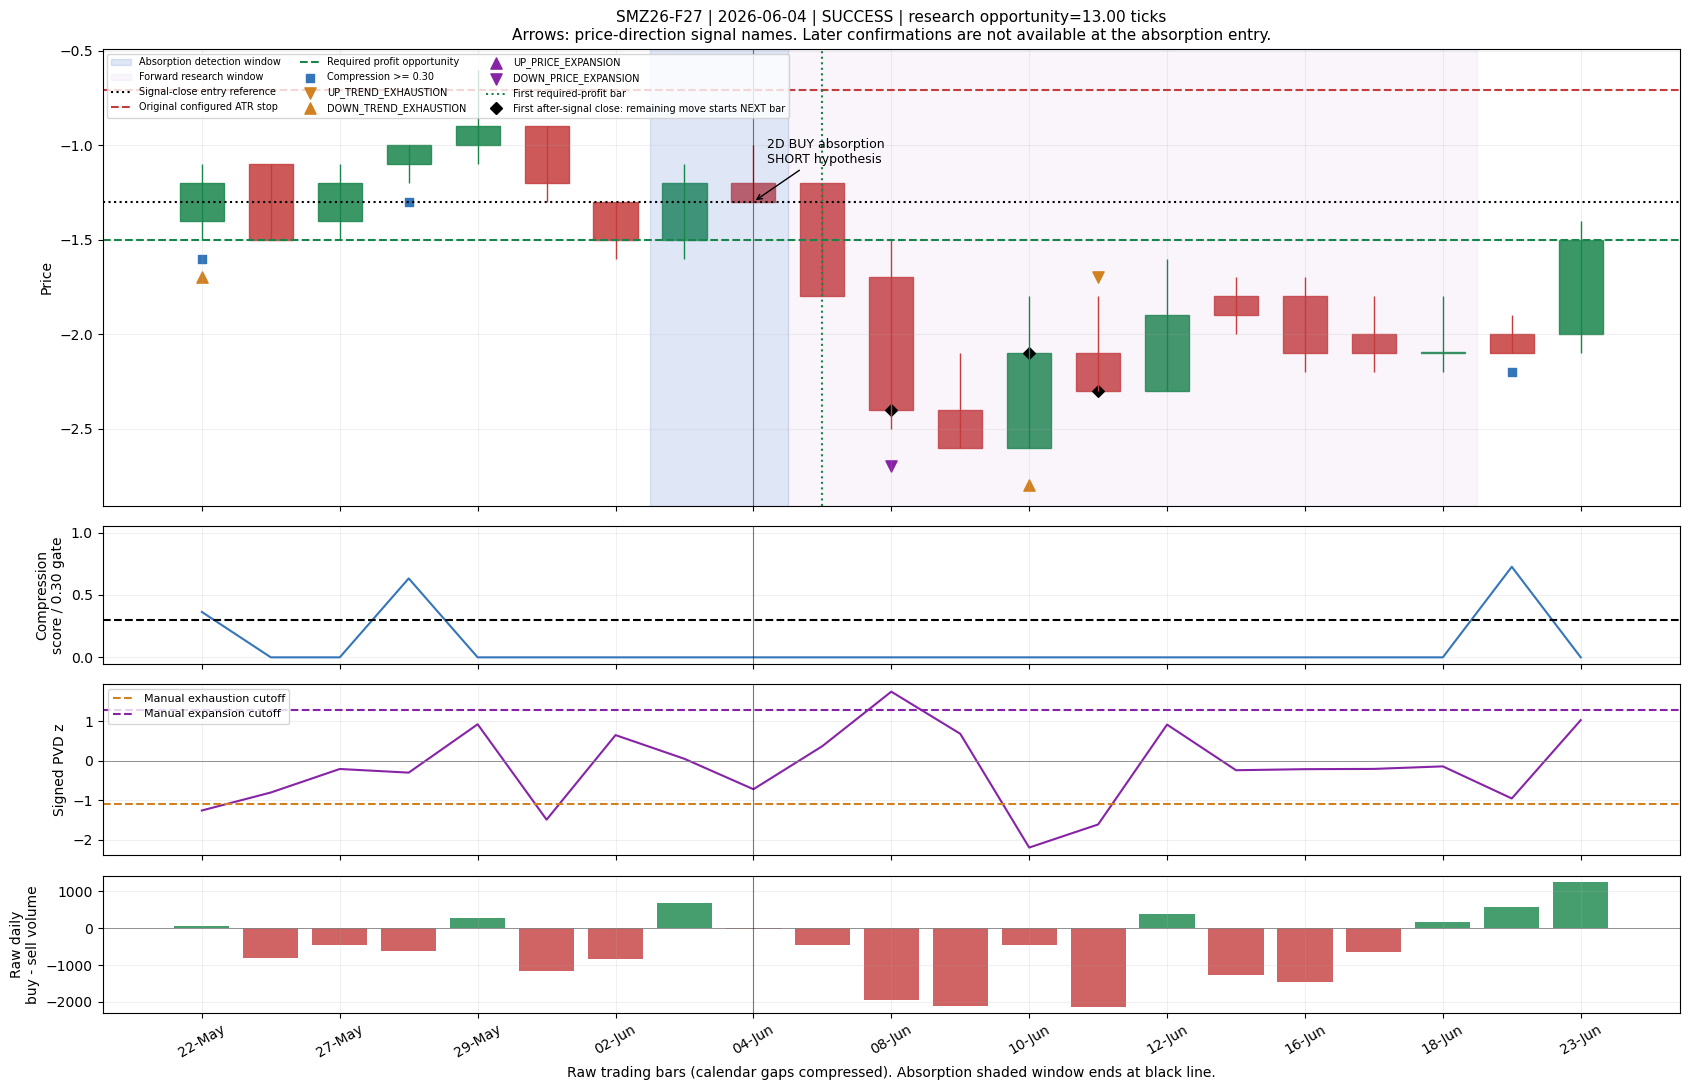

In [8]:
CASE_COLUMNS=["event_id","instrument","date","duration","absorption_side",
              "before_combination","during_combination","before_state","during_state",
              "candidate_group","candidate_prediction","actual_direction","terminal_move_ticks",
              "first_barrier","outcome","full_horizon"]
view("Event-by-event audit", "Direction numbers: +1=UP, -1=DOWN, 0=FLAT; n/a=incomplete/no prediction. Filter this table for the examples you noticed.",EVENTS[CASE_COLUMNS])

# EDIT: paste an exact event_id from the table for a specific case.
EVENT_ID = None
if EVENT_ID:
    selected=EVENTS.loc[EVENTS.event_id.eq(EVENT_ID)]
else:
    # Date-first examples per group, not selected by large profits.
    selected=EVENTS.sort_values("date").groupby("candidate_group",sort=False).head(1).head(4)
for row in selected.itertuples():
    display(Markdown(f"**{row.event_id}** — {row.candidate_group}; original outcome={row.outcome}; terminal move={row.terminal_move_ticks:.2f} ticks"))
    try:
        display(core.plot_event(RUN["instruments"][row.instrument],row.event_id))
    except ImportError as exc:
        print("Chart dependency missing:",exc)


## 7. Cross-front context + save outputs

Same signal on other fronts is supporting context. Ratio = matched unique anchors / eligible anchors. Window 0 means same day, 2 means +/-2 observed trading bars. Positive lag means other instrument's signal came later. Later confirmation cannot be used at the original entry time.

All research tables are saved for comparison as more cells are added. Existing hypotheses ko result dekhkar silently change mat karo; new idea ko separate hypothesis/cell banao.


In [9]:
import market_analysis.combined_signal_analysis.cross_front_analysis as cf
importlib.reload(cf)
CROSS=cf.analyze_cross_front_signals(RUN,windows=[0,1,2,5],related_product_groups=[["SM","BO"]])
view("Cross-front summary", "A signal matching several fronts counts once in the summary. Compression/PVD are daily signal observations, not episodes.",CROSS["product_summary"])
view("Cross-front instrument pairs", "match_ratio_a uses eligible A signals; match_ratio_b uses eligible B signals. Month gaps measure contract proximity.",CROSS["pair_table"])

SAVE_DIR=Path(RUN["output_dir"])/"hypothesis_research"
SAVE_DIR.mkdir(parents=True,exist_ok=True)
TABLES={"events":EVENTS,"baseline":BASELINE,"frequency":FREQUENCY,
        "combinations":COMBINATIONS,"hypotheses":HYPOTHESES,"failure_groups":FAILURE_GROUPS}
for name,table in TABLES.items():
    table.to_csv(SAVE_DIR/(name+".csv"),index=False)
print("Saved:",SAVE_DIR)


### Cross-front summary

A signal matching several fronts counts once in the summary. Compression/PVD are daily signal observations, not episodes.

,scope,signal,within_trading_bars,total_anchor_signals,eligible_anchor_signals,matched_anchor_signals,match_ratio
0,same_product:BO,ABS_BUY,0,45,45,20,0.44
1,same_product:BO,ABS_BUY,1,45,44,37,0.84
2,same_product:BO,ABS_BUY,2,45,42,38,0.90
3,same_product:BO,ABS_BUY,5,45,39,39,1.00
4,same_product:BO,ABS_SELL,0,34,34,8,0.24
5,same_product:BO,ABS_SELL,1,34,31,15,0.48
6,same_product:BO,ABS_SELL,2,34,31,20,0.65
7,same_product:BO,ABS_SELL,5,34,29,28,0.97
8,same_product:BO,COMPRESSION,0,79,79,59,0.75
9,same_product:BO,COMPRESSION,1,79,79,74,0.94


### Cross-front instrument pairs

match_ratio_a uses eligible A signals; match_ratio_b uses eligible B signals. Month gaps measure contract proximity.

,scope,instrument_a,instrument_b,structure_a,structure_b,signal,within_trading_bars,front_month_gap,back_month_gap,tenor_month_gap,total_signals_a,eligible_signals_a,matched_signals_a,match_ratio_a,total_signals_b,eligible_signals_b,matched_signals_b,match_ratio_b,mean_matched_gap_bars
0,same_product:BO,BOF27-H27,BOH27-K27,spread,spread,ABS_BUY,0,2,2,0,5,5,0,0.00,13,13,0,0.00,n/a
1,same_product:BO,BOF27-H27,BOH27-K27,spread,spread,ABS_BUY,1,2,2,0,5,5,3,0.60,13,12,2,0.17,1.00
2,same_product:BO,BOF27-H27,BOH27-K27,spread,spread,ABS_BUY,2,2,2,0,5,4,3,0.75,13,12,3,0.25,1.33
3,same_product:BO,BOF27-H27,BOH27-K27,spread,spread,ABS_BUY,5,2,2,0,5,4,4,1.00,13,11,5,0.45,1.89
4,same_product:BO,BOF27-H27,BOH27-K27,spread,spread,ABS_SELL,0,2,2,0,2,2,0,0.00,9,9,0,0.00,n/a
5,same_product:BO,BOF27-H27,BOH27-K27,spread,spread,ABS_SELL,1,2,2,0,2,2,0,0.00,9,9,0,0.00,n/a
6,same_product:BO,BOF27-H27,BOH27-K27,spread,spread,ABS_SELL,2,2,2,0,2,2,0,0.00,9,9,0,0.00,n/a
7,same_product:BO,BOF27-H27,BOH27-K27,spread,spread,ABS_SELL,5,2,2,0,2,2,1,0.50,9,8,2,0.25,3.00
8,same_product:BO,BOF27-H27,BOH27-K27,spread,spread,COMPRESSION,0,2,2,0,11,11,7,0.64,19,19,7,0.37,0.00
9,same_product:BO,BOF27-H27,BOH27-K27,spread,spread,COMPRESSION,1,2,2,0,11,11,11,1.00,19,19,10,0.53,0.33


Saved: C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\combined_signal_analysis\outputs\2026-10-08\hypothesis_research


In [10]:
import numpy as np
import pandas as pd
from IPython.display import display

# Existing RUN aur EVENTS reuse honge; koi API call nahi.
rows = []

for instrument, result in RUN["instruments"].items():
    daily = result["daily"].reset_index(drop=True)
    before_bars = int(result["settings"]["before_bars"])

    outcomes = EVENTS.loc[
        EVENTS["instrument"].eq(instrument)
    ].set_index("event_id")

    for event in result["events"].itertuples():
        start = int(event.window_start_index)
        end = int(event.signal_index)
        outcome = outcomes.loc[event.event_id]

        windows = {
            "Before": (max(0, start - before_bars), start, before_bars),
            "During": (start, end + 1, end - start + 1),
        }

        for phase, (left, right, required_bars) in windows.items():
            window = daily.iloc[left:right]

            # Incomplete indicator history ko "no PVD" nahi maanenge.
            known = (
                len(window) == required_bars
                and np.isfinite(window["pvd_z"]).all()
            )

            hits = window.loc[window["pvd_signal"].isin([
                "DOWN_TREND_EXHAUSTION",
                "UP_TREND_EXHAUSTION",
                "DOWN_PRICE_EXPANSION",
                "UP_PRICE_EXPANSION",
            ])]

            prediction = np.nan

            if known and not hits.empty:
                latest = hits.iloc[-1]["pvd_signal"]

                # Reversal hypothesis:
                # DOWN exhaustion/expansion -> UP
                # UP exhaustion/expansion   -> DOWN
                prediction = 1 if latest.startswith("DOWN") else -1

            actual = {"UP": 1, "DOWN": -1}.get(
                outcome["first_barrier"], np.nan
            )

            rows.append({
                "product": outcome["product"],
                "phase": phase,
                "known": known,
                "pvd_prediction": prediction,
                "actual": actual,
                "abs_prediction": outcome["abs_prediction"],
            })

comparison = pd.DataFrame(rows)
summary = []

for (product, phase), group in comparison.groupby(["product", "phase"]):
    has_pvd = group["pvd_prediction"].notna()
    testable = has_pvd & group["actual"].notna()
    tested = group.loc[testable]

    summary.append({
        "Product": product,
        "PVD kab": phase,
        "Total absorption": len(group),
        "PVD mila": int(has_pvd.sum()),
        "Testable cases": len(tested),
        "PVD sahi %": (
            100 * tested["actual"].eq(tested["pvd_prediction"]).mean()
            if len(tested) else np.nan
        ),
        "PVD opposite sahi %": (
            100 * tested["actual"].eq(-tested["pvd_prediction"]).mean()
            if len(tested) else np.nan
        ),
        "Absorption sahi %": (
            100 * tested["actual"].eq(tested["abs_prediction"]).mean()
            if len(tested) else np.nan
        ),
    })

PVD_SIMPLE = pd.DataFrame(summary)

print("SM aur BO separately pooled; har absorption event ek baar per phase.")
print("Before/During: us window ka latest PVD signal.")
print("Testable: PVD available aur future mein UP/DOWN target ka clear first hit.")
print("Same-bar both hits, no target hit, incomplete future: accuracy se excluded.")
display(PVD_SIMPLE.style.format(precision=1, na_rep="n/a"))

SM aur BO separately pooled; har absorption event ek baar per phase.
Before/During: us window ka latest PVD signal.
Testable: PVD available aur future mein UP/DOWN target ka clear first hit.
Same-bar both hits, no target hit, incomplete future: accuracy se excluded.


,Product,PVD kab,Total absorption,PVD mila,Testable cases,PVD sahi %,PVD opposite sahi %,Absorption sahi %
0,BO,Before,79,59,38,57.9,42.1,76.3
1,BO,During,79,38,25,64.0,36.0,84.0
2,SM,Before,52,37,24,41.7,58.3,50.0
3,SM,During,52,25,19,42.1,57.9,57.9


In [11]:
import numpy as np
import pandas as pd
from IPython.display import display

# Research rules — results dekhkar validate karne hain.
PVD_RULE = {
    "Before": "opposite",
    "During": "same",
}

PVD_TYPES = [
    "DOWN_TREND_EXHAUSTION", "UP_TREND_EXHAUSTION",
    "DOWN_PRICE_EXPANSION", "UP_PRICE_EXPANSION",
]

rows = []

for instrument, result in RUN["instruments"].items():
    daily = result["daily"].reset_index(drop=True)
    before_bars = int(result["settings"]["before_bars"])

    event_details = EVENTS.loc[
        EVENTS["instrument"].eq(instrument)
    ].set_index("event_id")

    for event in result["events"].itertuples():
        details = event_details.loc[event.event_id]
        start, end = int(event.window_start_index), int(event.signal_index)

        windows = {
            "Before": (max(0, start - before_bars), start, before_bars),
            "During": (start, end + 1, end - start + 1),
        }

        for phase, (left, right, expected_bars) in windows.items():
            window = daily.iloc[left:right]
            known = (
                len(window) == expected_bars
                and np.isfinite(window["pvd_z"]).all()
            )

            hits = window.loc[window["pvd_signal"].isin(PVD_TYPES)]

            if not known:
                group = "Unknown data"
            elif hits.empty:
                group = "No PVD"
            else:
                latest = hits.iloc[-1]["pvd_signal"]

                # PVD reversal interpretation: DOWN-labelled -> UP.
                prediction = 1 if latest.startswith("DOWN") else -1
                if PVD_RULE[phase] == "opposite":
                    prediction *= -1

                group = (
                    "Agree"
                    if prediction == details["abs_prediction"]
                    else "Disagree"
                )

            rows.append({
                "product": details["product"],
                "phase": phase,
                "group": group,
                "event_id": event.event_id,
                "outcome": details["outcome"],
                "payoff": details["research_payoff_ticks"],
            })

ABS_PVD = pd.DataFrame(rows)


def trade_stats(group):
    """Only resolved original absorption trades enter payoff/success averages."""
    resolved = group.loc[group["outcome"].isin(["SUCCESS", "FAILURE"])]

    return {
        "Signals": len(group),
        "Resolved": len(resolved),
        "Success %": (
            100 * resolved["outcome"].eq("SUCCESS").mean()
            if len(resolved) else np.nan
        ),
        "Expected ticks": (
            resolved["payoff"].mean() if len(resolved) else np.nan
        ),
    }


# TABLE 1: Which group has better original absorption performance?
group_rows = []

for (product, phase), sample in ABS_PVD.groupby(["product", "phase"]):
    for label, group in sample.groupby("group"):
        group_rows.append({
            "Product": product,
            "PVD kab": phase,
            "Group": label,
            **trade_stats(group),
            "Signals %": 100 * len(group) / len(sample),
        })

GROUP_RESULTS = pd.DataFrame(group_rows)

print("TABLE 1 — Agree / Disagree / No PVD performance")
print("Success % = profit target original ATR stop se pehle mila.")
print("Expected ticks = resolved original absorption trades ka average research payoff.")
print("Signals % = is group ke signals / total absorption signals.")
display(GROUP_RESULTS.style.format(precision=2, na_rep="n/a"))


# TABLE 2: Compare baseline with skipping only Disagree.
filter_rows = []

for (product, phase), sample in ABS_PVD.groupby(["product", "phase"]):
    baseline = trade_stats(sample)

    # No PVD / Unknown cases remain; ONLY Disagree removed.
    kept = sample.loc[sample["group"].ne("Disagree")]
    filtered = trade_stats(kept)

    filter_rows.append({
        "Product": product,
        "PVD kab": phase,
        "Original signals": baseline["Signals"],
        "Kept signals": filtered["Signals"],
        "Removed signals": baseline["Signals"] - filtered["Signals"],
        "Retained %": 100 * len(kept) / len(sample),
        "Original resolved": baseline["Resolved"],
        "Kept resolved": filtered["Resolved"],
        "Original success %": baseline["Success %"],
        "Filtered success %": filtered["Success %"],
        "Original expected ticks": baseline["Expected ticks"],
        "Filtered expected ticks": filtered["Expected ticks"],
        "Improvement ticks": (
            filtered["Expected ticks"] - baseline["Expected ticks"]
        ),
    })

FILTER_RESULTS = pd.DataFrame(filter_rows)

print("\nTABLE 2 — Disagree skip karne ka effect")
print("Positive Improvement ticks = retained trades ka average payoff higher.")
print("Retained % dekho: improvement ke liye kitne signals lose hue?")
display(FILTER_RESULTS.style.format(precision=2, na_rep="n/a"))

TABLE 1 — Agree / Disagree / No PVD performance
Success % = profit target original ATR stop se pehle mila.
Expected ticks = resolved original absorption trades ka average research payoff.
Signals % = is group ke signals / total absorption signals.


,Product,PVD kab,Group,Signals,Resolved,Success %,Expected ticks,Signals %
0,BO,Before,Agree,30,23,60.87,1.33,37.97
1,BO,Before,Disagree,29,20,75.00,1.65,36.71
2,BO,Before,No PVD,20,15,53.33,1.04,25.32
3,BO,During,Agree,20,15,86.67,2.36,25.32
4,BO,During,Disagree,18,12,66.67,1.27,22.78
5,BO,During,No PVD,41,31,51.61,0.91,51.90
6,SM,Before,Agree,11,7,85.71,16.27,21.15
7,SM,Before,Disagree,26,23,73.91,4.77,50.00
8,SM,Before,No PVD,15,15,86.67,10.84,28.85
9,SM,During,Agree,14,12,83.33,6.06,26.92



TABLE 2 — Disagree skip karne ka effect
Positive Improvement ticks = retained trades ka average payoff higher.
Retained % dekho: improvement ke liye kitne signals lose hue?


,Product,PVD kab,Original signals,Kept signals,Removed signals,Retained %,Original resolved,Kept resolved,Original success %,Filtered success %,Original expected ticks,Filtered expected ticks,Improvement ticks
0,BO,Before,79,50,29,63.29,58,38,63.79,57.89,1.36,1.21,-0.15
1,BO,During,79,61,18,77.22,58,46,63.79,63.04,1.36,1.39,0.02
2,SM,Before,52,26,26,50.00,45,22,80.00,86.36,8.58,12.57,3.98
3,SM,During,52,41,11,78.85,45,36,80.00,80.56,8.58,8.36,-0.22
